In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys
from pathlib import Path

current_path = Path.cwd()

if (current_path / "src").exists():
    PROJECT_ROOT = current_path
elif (current_path.parent / "src").exists():
    PROJECT_ROOT = current_path.parent
else:
    raise FileNotFoundError("No se encontró la carpeta src.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

from src.models import (
     PhantomQ0Params,
    PhantomQ0Model,
)

Project root: /Users/macbook/Usach/TesisxD/cosmo_singularities


In [2]:
params = PhantomQ0Params(
    A=1.0,
    nu=0.75,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
)

model = PhantomQ0Model(params)

t_values = np.linspace(0.0, 2.0, 500)

df = model.evaluate_background_t(t_values)

df.head()

,t,a,rho,Q,P,rho_eff,H,Hdot,w
0,0.000000,1.000000,1.000000,0.0,-2.000000,1.000000,0.577350,0.500000,-2.000000
1,0.004008,1.002321,1.006972,0.0,-2.012197,1.006972,0.579360,0.502612,-1.998264
2,0.008016,1.004655,1.014005,0.0,-2.024491,1.014005,0.581379,0.505243,-1.996529
3,0.012024,1.007003,1.021100,0.0,-2.036884,1.021100,0.583410,0.507892,-1.994793
4,0.016032,1.009364,1.028257,0.0,-2.049376,1.028257,0.585451,0.510559,-1.993058


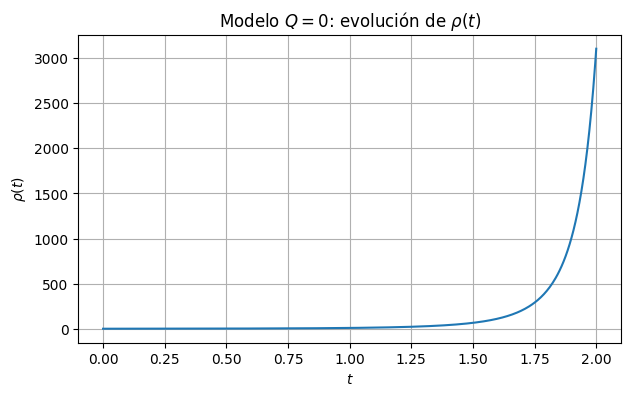

In [3]:
plt.figure(figsize=(7, 4))
plt.plot(df["t"], df["rho"])
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(r"Modelo $Q=0$: evolución de $\rho(t)$")
plt.grid(True)
plt.show()

In [4]:


import numpy as np
import matplotlib.pyplot as plt

import sys
from pathlib import Path

current_path = Path.cwd()

if (current_path / "src").exists():
    PROJECT_ROOT = current_path
elif (current_path.parent / "src").exists():
    PROJECT_ROOT = current_path.parent
else:
    raise FileNotFoundError("No se encontró la carpeta src.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

from src.models import (
     PhantomQAlphaRhoParams,
    PhantomQAlphaRhoModel
,
)

Project root: /Users/macbook/Usach/TesisxD/cosmo_singularities


In [5]:
params = PhantomQAlphaRhoParams(
    A=1.0,
    nu=0.75,
    alpha=0.5,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
)

model = PhantomQAlphaRhoModel(params)

ts = model.singular_time()
print("Tiempo singular:", ts)

t_values = np.linspace(0.0, 0.95 * ts, 500)

df = model.evaluate_background_t(t_values)

df.head()

Tiempo singular: 2.82842712474619


,t,a,rho,Q,P,rho_eff,H,Hdot,w
0,0.000000,1.000000,1.000000,0.500000,-2.000000,1.500000,0.707107,0.500000,-2.000000
1,0.005385,1.003822,1.007652,0.503826,-2.013385,1.511477,0.709807,0.502867,-1.998096
2,0.010770,1.007674,1.015377,0.507688,-2.026887,1.523065,0.712522,0.505755,-1.996192
3,0.016154,1.011555,1.023176,0.511588,-2.040508,1.534763,0.715254,0.508666,-1.994289
4,0.021539,1.015466,1.031050,0.515525,-2.054248,1.546575,0.718001,0.511599,-1.992385


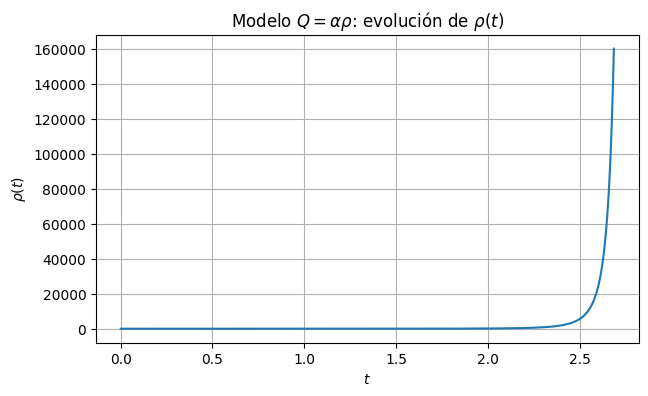

In [6]:
plt.figure(figsize=(7, 4))
plt.plot(df["t"], df["rho"])
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(r"Modelo $Q=\alpha\rho$: evolución de $\rho(t)$")
plt.grid(True)
plt.show()

In [7]:
params = PhantomQ0Params(A=1.0, nu=0.75, rho0=1.0)
model = PhantomQ0Model(params)

"evaluate_background_t" in dir(model)

True

# Probar dataset1

In [2]:
import numpy as np
import pandas as pd

from src.datasets import (
    build_phantom_q0_dataset,
    build_phantom_qalpha_dataset,
)

In [3]:
A_values = [0.5, 1.0, 2.0]

nu_values = [
    -1.0,
    -0.5,
    0.25,
    0.5,
    0.75,
    1.0,
    1.5,
    2.0,
]

rho0_values = [0.5, 1.0, 2.0]

df_q0 = build_phantom_q0_dataset(
    A_values=A_values,
    nu_values=nu_values,
    rho0_values=rho0_values,
    t_end_default=10.0,
    n_points=500,
    singular_fraction=0.95,
)

df_q0.head()

,model_name,A,nu,alpha,rho0,a0,t0,singularity_type,singular_time,valid_solution,...,a_max,H_initial,H_final,H_max,P_initial,P_final,P_abs_max,Hdot_initial,Hdot_final,Hdot_max
0,phantom_q0,0.5,-1.0,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,35129.050795,0.408248,1.369412,1.369412,-1.500000,-5.714740,5.714740,0.500000,0.044438,0.500000
1,phantom_q0,0.5,-1.0,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,54376.907471,0.577350,1.391178,1.391178,-1.500000,-5.892241,5.892241,0.250000,0.043058,0.250000
2,phantom_q0,0.5,-1.0,NaN,2.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,147751.395138,0.816497,1.449319,1.449319,-2.250000,-6.380921,6.380921,0.125000,0.039673,0.125000
3,phantom_q0,0.5,-0.5,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,191912.682973,0.408248,1.747403,1.747403,-1.207107,-9.325456,9.325456,0.353553,0.082601,0.353553
4,phantom_q0,0.5,-0.5,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,400309.791321,0.577350,1.794459,1.794459,-1.500000,-9.821124,9.821124,0.250000,0.080435,0.250000


In [4]:
df_q0["singularity_type"].value_counts()

singularity_type
Ambiguous                       42
Type II / Sudden singularity    18
Type IV                          9
Non singular                     3
Name: count, dtype: int64

In [5]:
df_q0["valid_solution"].value_counts()

valid_solution
False    42
True     30
Name: count, dtype: int64

In [6]:
df_q0.loc[~df_q0["valid_solution"], ["A", "nu", "rho0", "error_message"]].head(20)

,A,nu,rho0,error_message
12,0.5,0.75,0.5,math range error
13,0.5,0.75,1.0,math range error
14,0.5,0.75,2.0,math range error
15,0.5,1.00,0.5,La solución rho(t) dejó de ser real positiva p...
16,0.5,1.00,1.0,La solución rho(t) dejó de ser real positiva p...
17,0.5,1.00,2.0,La solución rho(t) dejó de ser real positiva p...
18,0.5,1.50,0.5,La solución rho(t) dejó de ser real positiva p...
19,0.5,1.50,1.0,La solución rho(t) dejó de ser real positiva p...
20,0.5,1.50,2.0,La solución rho(t) dejó de ser real positiva p...
21,0.5,2.00,0.5,La solución rho(t) dejó de ser real positiva p...


# Probar dataset2

In [7]:
A_values = [0.5, 1.0, 2.0]

nu_values = [
    -1.0,
    -0.5,
    0.25,
    0.5,
    0.75,
    1.0,
    1.5,
    2.0,
]

alpha_values = [-0.8, -0.5, 0.0, 0.5, 1.0, 2.0]

rho0_values = [0.5, 1.0, 2.0]

df_qalpha = build_phantom_qalpha_dataset(
    A_values=A_values,
    nu_values=nu_values,
    alpha_values=alpha_values,
    rho0_values=rho0_values,
    t_end_default=10.0,
    n_points=500,
    singular_fraction=0.95,
)

df_qalpha.head()

,model_name,A,nu,alpha,rho0,a0,t0,singularity_type,singular_time,valid_solution,...,a_max,H_initial,H_final,H_max,P_initial,P_final,P_abs_max,Hdot_initial,Hdot_final,Hdot_max
0,phantom_qalpha_rho,0.5,-1.0,-0.8,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,416.917716,0.182574,0.796908,0.796908,-1.50,-9.578418,9.578418,0.500,0.026244,0.500
1,phantom_qalpha_rho,0.5,-1.0,-0.8,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,473.848057,0.258199,0.802706,0.802706,-1.50,-9.716788,9.716788,0.250,0.025866,0.250
2,phantom_qalpha_rho,0.5,-1.0,-0.8,2.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,646.270400,0.365148,0.818668,0.818668,-2.25,-10.103007,10.103007,0.125,0.024868,0.125
3,phantom_qalpha_rho,0.5,-1.0,-0.5,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,3810.196812,0.288675,1.084084,1.084084,-1.50,-7.122334,7.122334,0.500,0.035454,0.500
4,phantom_qalpha_rho,0.5,-1.0,-0.5,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,4934.876552,0.408248,1.096418,1.096418,-1.50,-7.282122,7.282122,0.250,0.034661,0.250


In [8]:
df_qalpha["singularity_type"].value_counts()

singularity_type
Type II / Sudden singularity    108
Type I / Big Rip                108
Type III                        108
Type IV                          54
Ambiguous                        34
Non singular                     20
Name: count, dtype: int64

In [9]:
df_qalpha["valid_solution"].value_counts()

valid_solution
True     398
False     34
Name: count, dtype: int64

In [10]:
df_all = pd.concat([df_q0, df_qalpha], ignore_index=True)

df_all.head()

,model_name,A,nu,alpha,rho0,a0,t0,singularity_type,singular_time,valid_solution,...,a_max,H_initial,H_final,H_max,P_initial,P_final,P_abs_max,Hdot_initial,Hdot_final,Hdot_max
0,phantom_q0,0.5,-1.0,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,35129.050795,0.408248,1.369412,1.369412,-1.500000,-5.714740,5.714740,0.500000,0.044438,0.500000
1,phantom_q0,0.5,-1.0,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,54376.907471,0.577350,1.391178,1.391178,-1.500000,-5.892241,5.892241,0.250000,0.043058,0.250000
2,phantom_q0,0.5,-1.0,NaN,2.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,147751.395138,0.816497,1.449319,1.449319,-2.250000,-6.380921,6.380921,0.125000,0.039673,0.125000
3,phantom_q0,0.5,-0.5,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,191912.682973,0.408248,1.747403,1.747403,-1.207107,-9.325456,9.325456,0.353553,0.082601,0.353553
4,phantom_q0,0.5,-0.5,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,400309.791321,0.577350,1.794459,1.794459,-1.500000,-9.821124,9.821124,0.250000,0.080435,0.250000


In [16]:
df_all.to_csv("data/processed/phantom_models_dataset.csv", index=False)

In [18]:
from pathlib import Path

Path("data/processed").mkdir(parents=True, exist_ok=True)

In [19]:
df_all.groupby(["model_name", "singularity_type"]).size()

model_name          singularity_type            
phantom_q0          Ambiguous                        42
                    Non singular                      3
                    Type II / Sudden singularity     18
                    Type IV                           9
phantom_qalpha_rho  Ambiguous                        34
                    Non singular                     20
                    Type I / Big Rip                108
                    Type II / Sudden singularity    108
                    Type III                        108
                    Type IV                          54
dtype: int64

In [21]:
df_all[
    ["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
].head(20)

,model_name,A,nu,alpha,rho0,singularity_type,singular_time
0,phantom_q0,0.5,-1.00,NaN,0.5,Type II / Sudden singularity,NaN
1,phantom_q0,0.5,-1.00,NaN,1.0,Type II / Sudden singularity,NaN
2,phantom_q0,0.5,-1.00,NaN,2.0,Type II / Sudden singularity,NaN
3,phantom_q0,0.5,-0.50,NaN,0.5,Type II / Sudden singularity,NaN
4,phantom_q0,0.5,-0.50,NaN,1.0,Type II / Sudden singularity,NaN
5,phantom_q0,0.5,-0.50,NaN,2.0,Type II / Sudden singularity,NaN
6,phantom_q0,0.5,0.25,NaN,0.5,Type IV,NaN
7,phantom_q0,0.5,0.25,NaN,1.0,Type IV,NaN
8,phantom_q0,0.5,0.25,NaN,2.0,Type IV,NaN
9,phantom_q0,0.5,0.50,NaN,0.5,Non singular,NaN


In [22]:
df_qalpha_valid = df_qalpha[df_qalpha["valid_solution"]].copy()

df_qalpha_valid[
    df_qalpha_valid["nu"] == 0.75
][["A", "nu", "alpha", "rho0", "singular_time"]].sort_values("alpha")

,A,nu,alpha,rho0,singular_time
72,0.5,0.75,-0.8,0.5,2.456416
73,0.5,0.75,-0.8,1.0,2.065591
74,0.5,0.75,-0.8,2.0,1.736948
218,1.0,0.75,-0.8,2.0,0.868474
217,1.0,0.75,-0.8,1.0,1.032796
216,1.0,0.75,-0.8,0.5,1.228208
360,2.0,0.75,-0.8,0.5,0.614104
361,2.0,0.75,-0.8,1.0,0.516398
362,2.0,0.75,-0.8,2.0,0.434237
221,1.0,0.75,-0.5,2.0,1.373178


# Revision DataSet

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df_all = pd.read_csv("data/processed/phantom_models_dataset.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'data/processed/phantom_models_dataset.csv'

In [4]:
df_all = pd.read_csv("data/processed/phantom_models_dataset.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'data/processed/phantom_models_dataset.csv'

In [5]:
df_all = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "phantom_models_dataset.csv"
)

In [6]:
df_all.head()

,model_name,A,nu,alpha,rho0,a0,t0,singularity_type,singular_time,valid_solution,...,a_max,H_initial,H_final,H_max,P_initial,P_final,P_abs_max,Hdot_initial,Hdot_final,Hdot_max
0,phantom_q0,0.5,-1.0,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,35129.050795,0.408248,1.369412,1.369412,-1.500000,-5.714740,5.714740,0.500000,0.044438,0.500000
1,phantom_q0,0.5,-1.0,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,54376.907471,0.577350,1.391178,1.391178,-1.500000,-5.892241,5.892241,0.250000,0.043058,0.250000
2,phantom_q0,0.5,-1.0,NaN,2.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,147751.395138,0.816497,1.449319,1.449319,-2.250000,-6.380921,6.380921,0.125000,0.039673,0.125000
3,phantom_q0,0.5,-0.5,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,191912.682973,0.408248,1.747403,1.747403,-1.207107,-9.325456,9.325456,0.353553,0.082601,0.353553
4,phantom_q0,0.5,-0.5,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,400309.791321,0.577350,1.794459,1.794459,-1.500000,-9.821124,9.821124,0.250000,0.080435,0.250000


In [7]:
df_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   model_name        504 non-null    object 
 1   A                 504 non-null    float64
 2   nu                504 non-null    float64
 3   alpha             432 non-null    float64
 4   rho0              504 non-null    float64
 5   a0                504 non-null    float64
 6   t0                504 non-null    float64
 7   singularity_type  504 non-null    object 
 8   singular_time     216 non-null    float64
 9   valid_solution    504 non-null    bool   
 10  error_message     76 non-null     object 
 11  t_eval_min        428 non-null    float64
 12  t_eval_max        428 non-null    float64
 13  rho_initial       428 non-null    float64
 14  rho_final         428 non-null    float64
 15  rho_max           428 non-null    float64
 16  a_initial         428 non-null    float64
 1

In [8]:
df_all["valid_solution"].value_counts()

valid_solution
True     428
False     76
Name: count, dtype: int64

In [9]:
df_all.groupby(["model_name", "singularity_type"]).size()

model_name          singularity_type            
phantom_q0          Ambiguous                        42
                    Non singular                      3
                    Type II / Sudden singularity     18
                    Type IV                           9
phantom_qalpha_rho  Ambiguous                        34
                    Non singular                     20
                    Type I / Big Rip                108
                    Type II / Sudden singularity    108
                    Type III                        108
                    Type IV                          54
dtype: int64

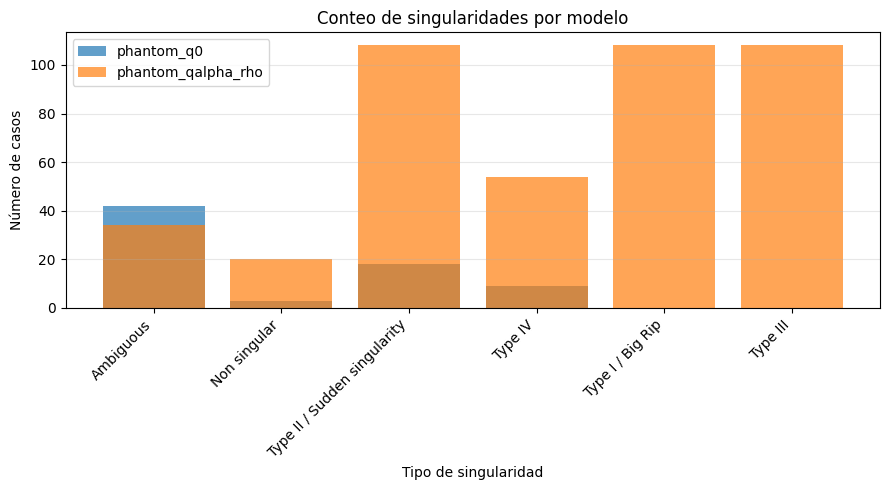

In [10]:
counts = (
    df_all
    .groupby(["model_name", "singularity_type"])
    .size()
    .reset_index(name="count")
)

plt.figure(figsize=(9, 5))

for model_name in counts["model_name"].unique():
    subset = counts[counts["model_name"] == model_name]
    plt.bar(
        subset["singularity_type"],
        subset["count"],
        alpha=0.7,
        label=model_name,
    )

plt.xlabel("Tipo de singularidad")
plt.ylabel("Número de casos")
plt.title("Conteo de singularidades por modelo")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
df_valid = df_all[df_all["valid_solution"]].copy()

df_ts = df_valid[np.isfinite(df_valid["singular_time"])].copy()

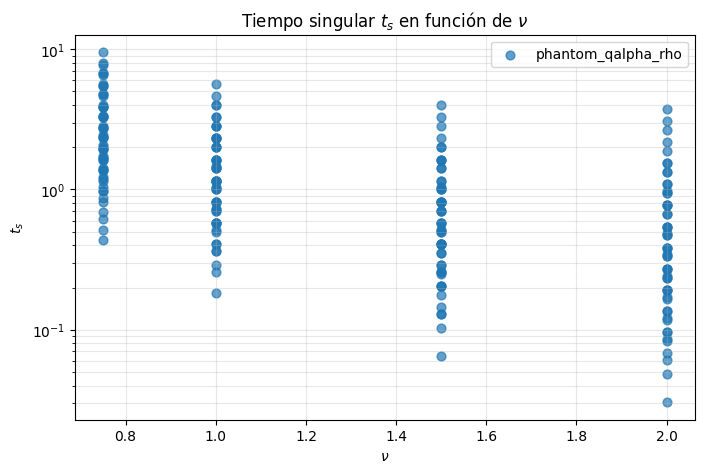

In [12]:
plt.figure(figsize=(8, 5))

for model_name in df_ts["model_name"].unique():
    subset = df_ts[df_ts["model_name"] == model_name]

    plt.scatter(
        subset["nu"],
        subset["singular_time"],
        s=40,
        alpha=0.7,
        label=model_name,
    )

plt.xlabel(r"$\nu$")
plt.ylabel(r"$t_s$")
plt.title(r"Tiempo singular $t_s$ en función de $\nu$")
plt.yscale("log")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [13]:
df_alpha = df_valid[
    df_valid["model_name"] == "phantom_qalpha_rho"
].copy()

df_alpha_ts = df_alpha[np.isfinite(df_alpha["singular_time"])].copy()

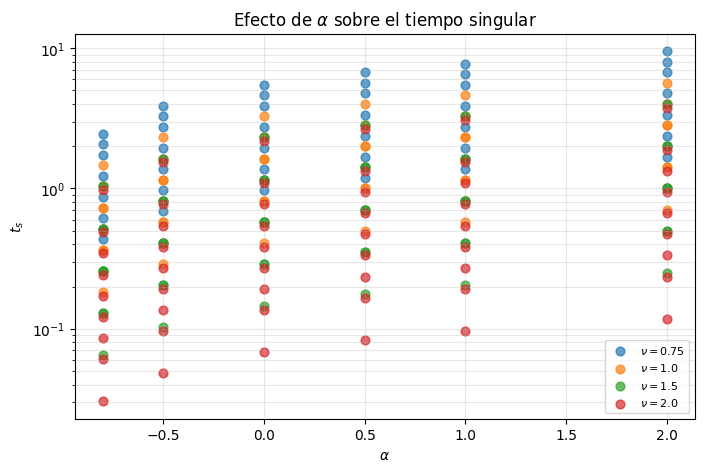

In [14]:
plt.figure(figsize=(8, 5))

for nu in sorted(df_alpha_ts["nu"].unique()):
    subset = df_alpha_ts[df_alpha_ts["nu"] == nu]

    plt.scatter(
        subset["alpha"],
        subset["singular_time"],
        s=40,
        alpha=0.7,
        label=rf"$\nu={nu}$",
    )

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$t_s$")
plt.title(r"Efecto de $\alpha$ sobre el tiempo singular")
plt.yscale("log")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [15]:
df_map = df_alpha.copy()

In [16]:
singularity_order = {
    "Type I / Big Rip": 1,
    "Type II / Sudden singularity": 2,
    "Type III": 3,
    "Type IV": 4,
    "Non singular": 0,
    "Ambiguous": -1,
}

df_map["singularity_code"] = df_map["singularity_type"].map(singularity_order)

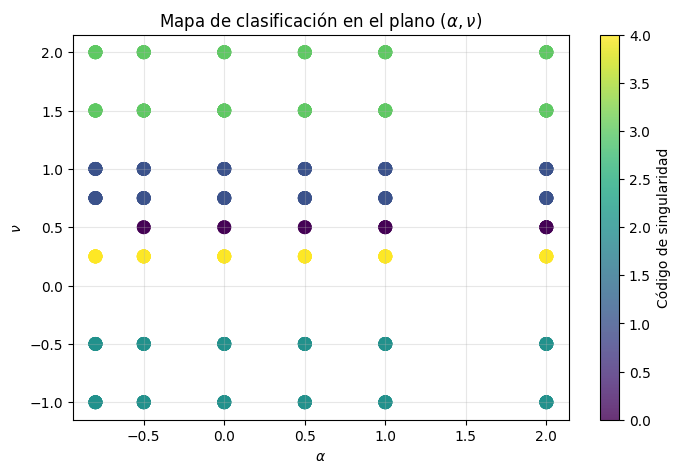

In [17]:
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    df_map["alpha"],
    df_map["nu"],
    c=df_map["singularity_code"],
    s=80,
    alpha=0.8,
)

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\nu$")
plt.title(r"Mapa de clasificación en el plano $(\alpha,\nu)$")
plt.grid(True, alpha=0.3)

cbar = plt.colorbar(scatter)
cbar.set_label("Código de singularidad")

plt.show()

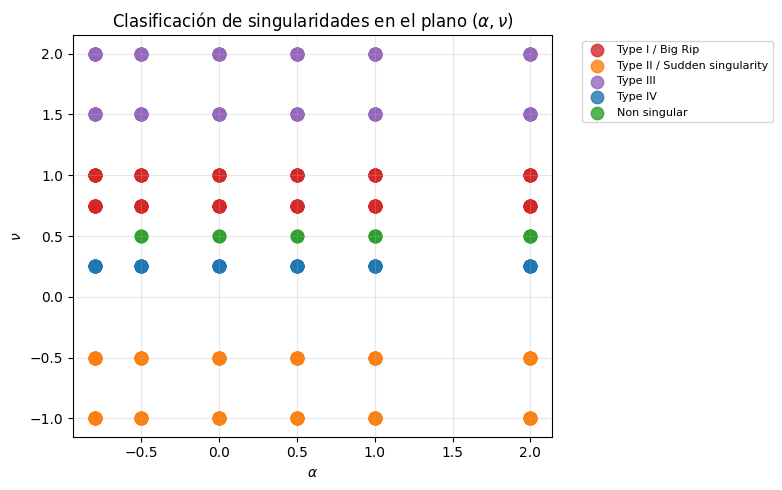

In [18]:
color_map = {
    "Type I / Big Rip": "tab:red",
    "Type II / Sudden singularity": "tab:orange",
    "Type III": "tab:purple",
    "Type IV": "tab:blue",
    "Non singular": "tab:green",
    "Ambiguous": "tab:gray",
}

plt.figure(figsize=(8, 5))

for singularity_type, color in color_map.items():
    subset = df_map[df_map["singularity_type"] == singularity_type]

    if len(subset) == 0:
        continue

    plt.scatter(
        subset["alpha"],
        subset["nu"],
        s=80,
        alpha=0.8,
        color=color,
        label=singularity_type,
    )

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\nu$")
plt.title(r"Clasificación de singularidades en el plano $(\alpha,\nu)$")
plt.legend(fontsize=8, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

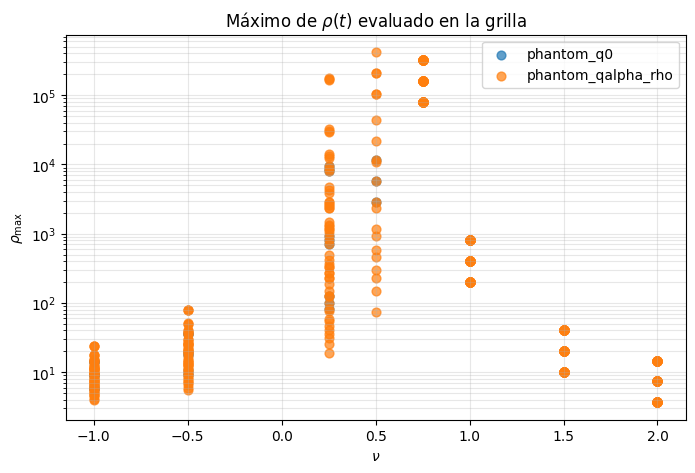

In [19]:
plt.figure(figsize=(8, 5))

for model_name in df_valid["model_name"].unique():
    subset = df_valid[df_valid["model_name"] == model_name]

    plt.scatter(
        subset["nu"],
        subset["rho_max"],
        s=40,
        alpha=0.7,
        label=model_name,
    )

plt.xlabel(r"$\nu$")
plt.ylabel(r"$\rho_{\max}$")
plt.yscale("log")
plt.title(r"Máximo de $\rho(t)$ evaluado en la grilla")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

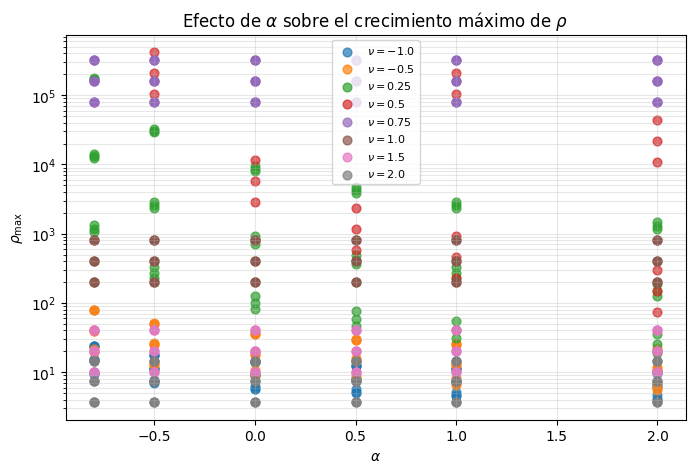

In [20]:
plt.figure(figsize=(8, 5))

for nu in sorted(df_alpha["nu"].unique()):
    subset = df_alpha[df_alpha["nu"] == nu]

    plt.scatter(
        subset["alpha"],
        subset["rho_max"],
        s=40,
        alpha=0.7,
        label=rf"$\nu={nu}$",
    )

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\rho_{\max}$")
plt.yscale("log")
plt.title(r"Efecto de $\alpha$ sobre el crecimiento máximo de $\rho$")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [21]:
df_q0 = df_valid[df_valid["model_name"] == "phantom_q0"].copy()
df_qalpha = df_valid[df_valid["model_name"] == "phantom_qalpha_rho"].copy()

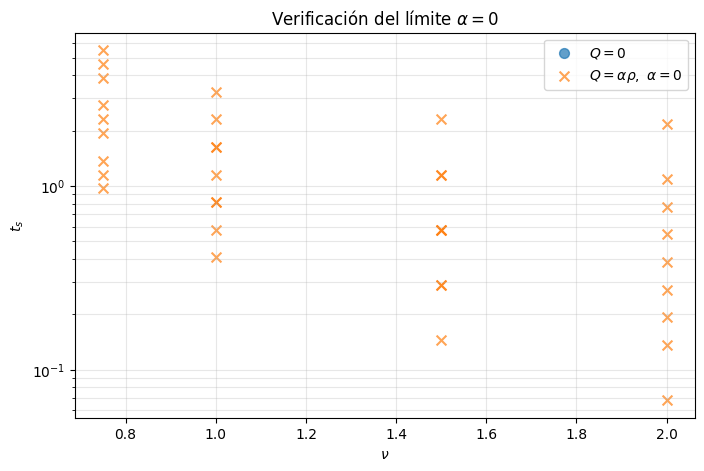

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_q0["nu"],
    df_q0["singular_time"],
    s=50,
    alpha=0.7,
    label=r"$Q=0$",
)

subset_alpha = df_qalpha[df_qalpha["alpha"] == 0.0]

plt.scatter(
    subset_alpha["nu"],
    subset_alpha["singular_time"],
    s=50,
    alpha=0.7,
    marker="x",
    label=r"$Q=\alpha\rho,\ \alpha=0$",
)

plt.xlabel(r"$\nu$")
plt.ylabel(r"$t_s$")
plt.yscale("log")
plt.title(r"Verificación del límite $\alpha=0$")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()